<a href="https://colab.research.google.com/github/sharifovlab/tabular-fm-vs-gbdt-dropout-binary-classification/blob/main/dropout_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, pickle
import numpy as np, pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold

SAVE = '/content/drive/MyDrive/dropout_uci'      # своя папка для нового проекта
os.makedirs(SAVE, exist_ok=True)

d = fetch_openml(data_id=46960, as_frame=True)  # UCI «Predict Students' Dropout and Academic Success» (TabArena)
X = d.data.copy()
y = (d.target == 'Dropout').astype(int).rename('dropout')

cat_cols = X.select_dtypes('category').columns.tolist()
X[cat_cols] = X[cat_cols].astype(str)

print(d.details['name'], '| строк, колонок:', X.shape, '| категориальных:', len(cat_cols))
print('доля отчислений:', round(y.mean(), 3), '| пропусков:', X.isnull().sum().sum())
print('уникальных значений безработицы:', X['Unemployment_rate'].nunique())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results, log, scaling_log = {}, [], []
SIZES = (250, 500, 1000, 2000, 3000)    # для run_scaling: в фолде ~2 830 строк
print(X_train.shape, X_test.shape)

Mounted at /content/drive
students_dropout_and_academic_success | строк, колонок: (4424, 36) | категориальных: 17
доля отчислений: 0.321 | пропусков: 0
уникальных значений безработицы: 10
(3539, 36) (885, 36)


In [2]:
import os, gc, time, pickle, psutil, torch
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss

def save_state():
    state = {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test,
             'cat_cols': cat_cols, 'results': results, 'log': log, 'scaling_log': scaling_log}
    with open(f'{SAVE}/state.pkl', 'wb') as f:
        pickle.dump(state, f)
    print('сохранено:', list(results.keys()))

def sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def ram_gb():
    return psutil.Process(os.getpid()).memory_info().rss / 1e9

def model_size(model):
    try:
        size_mb = round(len(pickle.dumps(model)) / 1e6, 1)
    except Exception:
        size_mb = None
    try:
        n_params = sum(p.numel() for v in vars(model).values()
                       if isinstance(v, torch.nn.Module) for p in v.parameters())
    except Exception:
        n_params = 0
    return size_mb, (n_params or None)

def cold_start(make_model, Xtr, fit_kwargs=None, n=1000):
    idx = np.arange(n)
    for _ in range(2):                     # первый прогон может качать веса — засекаем второй
        free_memory()
        t0 = time.perf_counter()
        m = make_model()
        kw = fit_kwargs(Xtr.iloc[idx], y_train.iloc[idx]) if fit_kwargs else {}
        m.fit(Xtr.iloc[idx], y_train.iloc[idx], **kw)
        m.predict_proba(Xtr.iloc[[0]])
        sync()
        t = time.perf_counter() - t0
        del m
    free_memory()
    return t

def latency_ms(model, X, n=20):
    x = X.iloc[[0]]
    model.predict_proba(x)
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        model.predict_proba(x)
        sync()
        times.append(time.perf_counter() - t0)
    return float(np.median(times) * 1000)

def recall_top(y, p, share=0.2):
    """Какую долю всех отчислившихся мы охватим, поговорив с share студентов с наибольшим риском."""
    top = np.argsort(-p)[: int(len(p) * share)]
    return y[top].sum() / y.sum()

def run_cv(name, make_model, Xtr, Xte, params, version, mode, device=None, fit_kwargs=None,
           gpu_required=None, tuning_s=0, update_on_new_data='', n_params=None, n_latency=20, notes=''):
    device = device or (torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
    print('cold start ...')
    cold_s = cold_start(make_model, Xtr, fit_kwargs)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    ram_peak = ram_gb()
    oof, test_pred = np.zeros(len(Xtr)), np.zeros(len(Xte))
    fit_t, pred_t, aucs = [], [], []
    model = None
    for k, (tr, va) in enumerate(skf.split(Xtr, y_train)):
        model = None
        free_memory()
        model = make_model()
        kw = fit_kwargs(Xtr.iloc[va], y_train.iloc[va]) if fit_kwargs else {}
        t0 = time.perf_counter()
        model.fit(Xtr.iloc[tr], y_train.iloc[tr], **kw)
        sync(); fit_t.append(time.perf_counter() - t0)
        ram_peak = max(ram_peak, ram_gb())
        t0 = time.perf_counter()
        oof[va] = model.predict_proba(Xtr.iloc[va])[:, 1]
        test_pred += model.predict_proba(Xte)[:, 1] / 5
        sync(); pred_t.append(time.perf_counter() - t0)
        ram_peak = max(ram_peak, ram_gb())
        aucs.append(roc_auc_score(y_train.iloc[va], oof[va]))
        print(f'fold {k}: AUC {aucs[-1]:.4f}   fit {fit_t[-1]:.1f} c   predict {pred_t[-1]:.1f} c')
    print('latency и размер модели ...')
    lat = latency_ms(model, Xte, n_latency)
    size_mb, auto_params = model_size(model)
    gpu_peak = round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else None
    model = None
    free_memory()
    n_pred = len(va) + len(Xte)
    fit_med, pred_med = float(np.median(fit_t)), float(np.median(pred_t))
    results[name] = {'oof': oof, 'test': test_pred}
    log.append({
        'model': name, 'mode': mode, 'version': version, 'params': str(params), 'notes': notes,
        'device': device, 'cpu_cores': os.cpu_count(), 'gpu_required': gpu_required,
        'cold_start_s': round(cold_s, 2), 'fit_s': round(fit_med, 2), 'tuning_s': tuning_s,
        'predict_s': round(pred_med, 2), 'throughput_rows_per_s': round(n_pred / pred_med),
        'latency_1row_ms': round(lat, 1), 'gpu_peak_gb': gpu_peak, 'ram_peak_gb': round(ram_peak, 2),
        'model_size_mb': size_mb, 'n_params': n_params or auto_params,
        'train_rows': len(tr), 'predict_rows': n_pred, 'update_on_new_data': update_on_new_data,
        'cv_auc': round(float(np.mean(aucs)), 4), 'cv_auc_std': round(float(np.std(aucs)), 4),
        'cv_pr_auc': round(average_precision_score(y_train, oof), 4),
        'recall_top20': round(recall_top(y_train.values, oof), 4),
    })
    save_state()
    print(f'CV AUC {np.mean(aucs):.4f} ± {np.std(aucs):.4f}   latency {lat:.1f} мс   cold start {cold_s:.1f} c')

def run_scaling(name, make_model, Xtr, sizes=SIZES, fit_kwargs=None):
    tr, va = next(skf.split(Xtr, y_train))
    for n in sizes:
        idx = tr if n >= len(tr) else train_test_split(tr, train_size=n, stratify=y_train.iloc[tr], random_state=42)[0]
        free_memory()
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        row, model = {'model': name, 'train_rows': len(idx)}, None
        try:
            model = make_model()
            kw = fit_kwargs(Xtr.iloc[va], y_train.iloc[va]) if fit_kwargs else {}
            t0 = time.perf_counter()
            model.fit(Xtr.iloc[idx], y_train.iloc[idx], **kw)
            sync(); row['fit_s'] = round(time.perf_counter() - t0, 2)
            t0 = time.perf_counter()
            p = model.predict_proba(Xtr.iloc[va])[:, 1]
            sync(); row['predict_s'] = round(time.perf_counter() - t0, 2)
            row['auc'] = round(roc_auc_score(y_train.iloc[va], p), 4)
            row['gpu_peak_gb'] = round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else None
            row['status'] = 'ok'
        except Exception as e:
            if 'out of memory' not in str(e).lower():
                raise
            row['status'] = 'OOM'
        finally:
            model = None
            free_memory()
        scaling_log.append(row)
        print(row)
    save_state()

print('функции готовы')

функции готовы


In [ ]:
import sys
!{sys.executable} -m pip install -q catboost
import sklearn, catboost, xgboost
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

# 1) логистическая регрессия
num_cols = [c for c in X_train.columns if c not in cat_cols]
make_lr = lambda: make_pipeline(
    ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols), ('num', StandardScaler(), num_cols)]),
    LogisticRegression(max_iter=5000))
run_cv('LogReg', make_lr, X_train, X_test, params={'C': 1.0, 'max_iter': 5000},
       version=f'scikit-learn {sklearn.__version__}', mode='baseline', device='CPU', gpu_required=False,
       update_on_new_data='переобучение', notes='линейная модель, без подбора')
run_scaling('LogReg', make_lr, X_train)



# 2) CatBoost — те же настройки, что в старом проекте
cb_params = dict(iterations=2000, learning_rate=0.05, eval_metric='AUC', early_stopping_rounds=100,
                 random_seed=42, verbose=0)
cb_fit = lambda Xv, yv: {'cat_features': cat_cols, 'eval_set': (Xv, yv)}
run_cv('CatBoost', lambda: CatBoostClassifier(**cb_params), X_train, X_test,
       params=cb_params, version=f'catboost {catboost.__version__}', mode='baseline', device='CPU',
       fit_kwargs=cb_fit, gpu_required=False, update_on_new_data='переобучение',
       notes='без подбора гиперпараметров; early stopping по валидационному фолду')
run_scaling('CatBoost', lambda: CatBoostClassifier(**cb_params), X_train, fit_kwargs=cb_fit)



# 3) XGBoost — те же настройки
X_train_xgb, X_test_xgb = X_train.copy(), X_test.copy()
for c in cat_cols:
    cats = pd.CategoricalDtype(sorted(X_train[c].unique()))
    X_train_xgb[c] = X_train[c].astype(cats)
    X_test_xgb[c] = X_test[c].astype(cats)
xgb_params = dict(n_estimators=2000, learning_rate=0.05, max_depth=6, tree_method='hist',
                  enable_categorical=True, eval_metric='auc', early_stopping_rounds=100,
                  random_state=42, n_jobs=-1)
xgb_fit = lambda Xv, yv: {'eval_set': [(Xv, yv)], 'verbose': False}
run_cv('XGBoost', lambda: XGBClassifier(**xgb_params), X_train_xgb, X_test_xgb,
       params=xgb_params, version=f'xgboost {xgboost.__version__}', mode='baseline', device='CPU',
       fit_kwargs=xgb_fit, gpu_required=False, update_on_new_data='переобучение',
       notes='без подбора гиперпараметров; early stopping по валидационному фолду')
run_scaling('XGBoost', lambda: XGBClassifier(**xgb_params), X_train_xgb, fit_kwargs=xgb_fit)

pd.DataFrame(log).set_index('model')[['cv_auc', 'cv_auc_std', 'cv_pr_auc', 'recall_top20', 'fit_s', 'latency_1row_ms']]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.0 MB/s eta 0:00:00
cold start ...
fold 0: AUC 0.9164   fit 0.5 c   predict 0.0 c
fold 1: AUC 0.9268   fit 0.6 c   predict 0.1 c
fold 2: AUC 0.9373   fit 0.1 c   predict 0.0 c
fold 3: AUC 0.9339   fit 0.1 c   predict 0.0 c
fold 4: AUC 0.9175   fit 0.1 c   predict 0.0 c
latency и размер модели ...
сохранено: ['LogReg']
CV AUC 0.9264 ± 0.0084   latency 7.2 мс   cold start 0.2 c
{'model': 'LogReg', 'train_rows': 250, 'fit_s': 0.03, 'predict_s': 0.02, 'auc': np.float64(0.8734), 'gpu_peak_gb': 0.0, 'status': 'ok'}
{'model': 'LogReg', 'train_rows': 500, 'fit_s': 0.04, 'predict_s': 0.02, 'auc': np.float64(0.8915), 'gpu_peak_gb': 0.0, 'status': 'ok'}
{'model': 'LogReg', 'train_rows': 1000, 'fit_s': 0.05, 'predict_s': 0.02, 'auc': np.float64(0.913), 'gpu_peak_gb': 0.0, 'status': 'ok'}
{'model': 'LogReg', 'train_rows': 2000, 'fit_s': 0.1, 'predict_s': 0.02, 'auc': np.float64(0.9164), 'gpu_peak_gb': 0.0, 'status': 'ok'}
{'model': 'LogReg',

,cv_auc,cv_auc_std,cv_pr_auc,recall_top20,fit_s,latency_1row_ms
model,,,,,,
LogReg,0.9264,0.0084,0.8878,0.5849,0.14,7.2
CatBoost,0.9259,0.0086,0.8837,0.5866,5.38,0.9
XGBoost,0.9185,0.0057,0.8649,0.5778,0.77,6.6


In [ ]:
#TabICLv2 (zero-shot)
import sys
!{sys.executable} -m pip install -q tabicl==2.2.0
from importlib.metadata import version
from tabicl import TabICLClassifier

tabicl_params = dict(checkpoint_version='tabicl-classifier-v2-20260212.ckpt', n_estimators=8,
                     device='cuda', random_state=42)
make_tabicl = lambda: TabICLClassifier(**tabicl_params)
_ = make_tabicl().fit(X_train.iloc[:500], y_train.iloc[:500]).predict_proba(X_train.iloc[:5])   # скачивание весов + прогрев

run_cv('TabICLv2', make_tabicl, X_train, X_test, params=tabicl_params,
       version=f"tabicl {version('tabicl')}, {tabicl_params['checkpoint_version']}",
       mode='zero-shot', gpu_required=True, update_on_new_data='добавить строки в контекст',
       n_latency=5, notes='без fine-tuning; настройки по умолчанию')
run_scaling('TabICLv2', make_tabicl, X_train)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.4/310.4 kB 12.8 MB/s eta 0:00:00


INFO: You are downloading 'tabicl-classifier-v2-20260212.ckpt', the latest best-performing version, used in our TabICLv2 paper.

Checkpoint 'tabicl-classifier-v2-20260212.ckpt' not cached.



tabicl-classifier-v2-20260212.ckpt: reconstructing file:   0%|          |  0.00B /  110MB            

tabicl-classifier-v2-20260212.ckpt: downloading bytes:           |  0.00B            

cold start ...


...

fold 4: AUC 0.9224   fit 0.7 c   predict 2.9 c
latency и размер модели ...
сохранено: ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2']
CV AUC 0.9291 ± 0.0113   latency 1179.4 мс   cold start 1.5 c
{'model': 'TabICLv2', 'train_rows': 250, 'fit_s': 0.51, 'predict_s': 0.68, 'auc': np.float64(0.8894), 'gpu_peak_gb': 0.95, 'status': 'ok'}
{'model': 'TabICLv2', 'train_rows': 500, 'fit_s': 0.53, 'predict_s': 0.92, 'auc': np.float64(0.8995), 'gpu_peak_gb': 1.18, 'status': 'ok'}
{'model': 'TabICLv2', 'train_rows': 1000, 'fit_s': 1.02, 'predict_s': 1.43, 'auc': np.float64(0.9091), 'gpu_peak_gb': 1.63, 'status': 'ok'}


/usr/local/lib/python3.13/dist-packages/tabicl/_sklearn/preprocessing.py:138: UserWarning: The following categorical columns have a cardinality above 40: ['Fathers_occupation']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.
  warnings.warn(


{'model': 'TabICLv2', 'train_rows': 2000, 'fit_s': 1.52, 'predict_s': 1.19, 'auc': np.float64(0.9121), 'gpu_peak_gb': 1.57, 'status': 'ok'}


/usr/local/lib/python3.13/dist-packages/tabicl/_sklearn/preprocessing.py:138: UserWarning: The following categorical columns have a cardinality above 40: ['Fathers_occupation']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.
  warnings.warn(


{'model': 'TabICLv2', 'train_rows': 2831, 'fit_s': 0.72, 'predict_s': 1.49, 'auc': np.float64(0.9187), 'gpu_peak_gb': 2.01, 'status': 'ok'}
сохранено: ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2']


In [ ]:
#TabPFN-3.5 (zero-shot)
!{sys.executable} -m pip install -q --upgrade tabpfn
from google.colab import userdata
os.environ['TABPFN_TOKEN'] = userdata.get('TABPFN_TOKEN')

import math
from safetensors import safe_open
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion

X_train_pfn, X_test_pfn = X_train.copy(), X_test.copy()
for c in cat_cols:
    cats = pd.CategoricalDtype(sorted(X_train[c].unique()))
    X_train_pfn[c] = X_train[c].astype(cats)
    X_test_pfn[c] = X_test[c].astype(cats)

make_pfn = lambda: TabPFNClassifier.create_default_for_version(ModelVersion.V3_5)
_ = make_pfn().fit(X_train_pfn.iloc[:500], y_train.iloc[:500]).predict_proba(X_train_pfn.iloc[:5])   # скачивание + прогрев
pfn_params = make_pfn().get_params()
with safe_open(pfn_params['model_path'], framework='pt') as f:
    pfn_n_params = sum(math.prod(f.get_slice(k).get_shape()) for k in f.keys())

run_cv('TabPFN-3.5', make_pfn, X_train_pfn, X_test_pfn, params=pfn_params,
       version=f"tabpfn {version('tabpfn')}, v3.5", mode='zero-shot', gpu_required=True,
       update_on_new_data='добавить строки в контекст', n_params=pfn_n_params, n_latency=5,
       notes='настройки по умолчанию; весь контекст фолда (урезать не нужно)')
run_scaling('TabPFN-3.5', make_pfn, X_train_pfn)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 44.9 MB/s eta 0:00:00


tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

cold start ...
fold 0: AUC 0.9231   fit 0.7 c   predict 8.7 c
fold 1: AUC 0.9256   fit 0.7 c   predict 9.2 c
fold 2: AUC 0.9453   fit 0.7 c   predict 9.2 c
fold 3: AUC 0.9462   fit 0.7 c   predict 8.6 c
fold 4: AUC 0.9285   fit 0.7 c   predict 8.3 c
latency и размер модели ...
сохранено: ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2', 'TabPFN-3.5']
CV AUC 0.9337 ± 0.0100   latency 3308.0 мс   cold start 1.7 c
{'model': 'TabPFN-3.5', 'train_rows': 250, 'fit_s': 0.66, 'predict_s': 0.85, 'auc': np.float64(0.8962), 'gpu_peak_gb': 2.28, 'status': 'ok'}
{'model': 'TabPFN-3.5', 'train_rows': 500, 'fit_s': 0.59, 'predict_s': 1.12, 'auc': np.float64(0.8987), 'gpu_peak_gb': 2.65, 'status': 'ok'}
{'model': 'TabPFN-3.5', 'train_rows': 1000, 'fit_s': 0.6, 'predict_s': 1.68, 'auc': np.float64(0.9111), 'gpu_peak_gb': 3.38, 'status': 'ok'}
{'model': 'TabPFN-3.5', 'train_rows': 2000, 'fit_s': 0.64, 'predict_s': 2.92, 'auc': np.float64(0.9176), 'gpu_peak_gb': 4.84, 'status': 'ok'}
{'model': 'TabPFN-3.5', 

In [ ]:
!{sys.executable} -m pip install -q structured-data-models==0.2.1
import sdm
import torch.nn.functional as F

class KumoClassifier:
    """Kumo Tabular с fit / predict_proba, как у sklearn (fit запоминает контекст, работа — в predict_proba)."""
    def __init__(self, size='small', num_estimators=8, random_state=42):
        self.size, self.num_estimators, self.random_state = size, num_estimators, random_state
        self.model = sdm.models.KumoTabular(task='classification', size=size, device='cuda')

    def fit(self, X, y):
        self.stypes_ = sdm.infer_stypes(X)
        self.x_ctx_ = sdm.TableTensor.from_pandas(df=X, stypes=self.stypes_, device='cuda')
        y_df = y.astype(int).rename('target').to_frame()
        self.y_ctx_ = sdm.TableTensor.from_pandas(df=y_df, stypes={'target': 'categorical'}, device='cuda')
        return self

    def predict_proba(self, X):
        x_q = sdm.TableTensor.from_pandas(df=X, stypes=self.stypes_, device='cuda')
        gen = torch.Generator('cuda').manual_seed(self.random_state)
        with torch.amp.autocast('cuda', dtype=torch.float16):
            out = self.model(x_context=self.x_ctx_, y_context=self.y_ctx_, x_query=x_q,
                             num_estimators=self.num_estimators, generator=gen)
        cols = out.columns[sdm.Stype.numerical]
        if '1' not in cols:
            raise ValueError(f'неожиданные колонки ответа: {cols}')
        p1 = out.numerical[..., cols.index('1')].float().cpu().numpy()
        return np.column_stack([1 - p1, p1])

# патч GQA для Medium: на T4 нет экономного ядра для GQA; результат математически тот же (Small не затрагивает)
if not hasattr(F, '_sdpa_orig'):
    F._sdpa_orig = F.scaled_dot_product_attention
def _sdpa_without_gqa(query, key, value, *args, enable_gqa=False, **kwargs):
    if enable_gqa and key.size(-3) != query.size(-3):
        rep = query.size(-3) // key.size(-3)
        key = key.repeat_interleave(rep, dim=-3)
        value = value.repeat_interleave(rep, dim=-3)
    return F._sdpa_orig(query, key, value, *args, **kwargs)
F.scaled_dot_product_attention = _sdpa_without_gqa

for size in ['small', 'medium']:
    name = f'Kumo-{size.capitalize()}'
    kp = dict(size=size, num_estimators=8, random_state=42)
    make = lambda p=kp: KumoClassifier(**p)
    run_cv(name, make, X_train, X_test,
           params={**kp, 'autocast': 'float16', 'kv_cache': False, 'gqa_patch': size == 'medium'},
           version=f"sdm {version('structured-data-models')}, nvidia/Kumo-Tabular v1.0.1 {size}",
           mode='zero-shot', gpu_required=True, update_on_new_data='добавить строки в контекст', n_latency=5,
           notes='официальные настройки NVIDIA для TabArena: 8 копий, float16, без KV-кеша, весь контекст')
    run_scaling(name, make, X_train)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 283.7/283.7 kB 6.2 MB/s eta 0:00:00
cold start ...


config.json:   0%|          | 0.00/423 [00:00<?, ?B/s]

small/classifier.pt: reconstructing file:   0%|          |  0.00B /  110MB            

small/classifier.pt: downloading bytes:           |  0.00B            

fold 0: AUC 0.9206   fit 0.0 c   predict 3.1 c
fold 1: AUC 0.9265   fit 0.0 c   predict 3.1 c
fold 2: AUC 0.9394   fit 0.0 c   predict 3.2 c
fold 3: AUC 0.9456   fit 0.0 c   predict 3.2 c
fold 4: AUC 0.9269   fit 0.0 c   predict 3.2 c
latency и размер модели ...
сохранено: ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2', 'TabPFN-3.5', 'Kumo-Small']
CV AUC 0.9318 ± 0.0092   latency 1240.2 мс   cold start 0.7 c
{'model': 'Kumo-Small', 'train_rows': 250, 'fit_s': 0.01, 'predict_s': 0.51, 'auc': np.float64(0.8969), 'gpu_peak_gb': 0.24, 'status': 'ok'}
{'model': 'Kumo-Small', 'train_rows': 500, 'fit_s': 0.01, 'predict_s': 0.55, 'auc': np.float64(0.9002), 'gpu_peak_gb': 0.28, 'status': 'ok'}
{'model': 'Kumo-Small', 'train_rows': 1000, 'fit_s': 0.01, 'predict_s': 0.71, 'auc': np.float64(0.9077), 'gpu_peak_gb': 0.34, 'status': 'ok'}
{'model': 'Kumo-Small', 'train_rows': 2000, 'fit_s': 0.02, 'predict_s': 1.09, 'auc': np.float64(0.9123), 'gpu_peak_gb': 0.46, 'status': 'ok'}
{'model': 'Kumo-Small', 

medium/classifier.pt: reconstructing file:   0%|          |  0.00B /  246MB            

medium/classifier.pt: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:2954: UserWarning: Mismatch dtype between input and weight: input dtype = c10::Half, weight dtype = float, Cannot dispatch to fused implementation. (Triggered internally at /pytorch/aten/src/ATen/native/layer_norm.cpp:344.)
  return torch.rms_norm(input, normalized_shape, weight, eps)


fold 0: AUC 0.9253   fit 0.0 c   predict 7.2 c
fold 1: AUC 0.9307   fit 0.0 c   predict 7.4 c
fold 2: AUC 0.9428   fit 0.0 c   predict 7.8 c
fold 3: AUC 0.9502   fit 0.0 c   predict 8.2 c
fold 4: AUC 0.9307   fit 0.0 c   predict 8.5 c
latency и размер модели ...
сохранено: ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2', 'TabPFN-3.5', 'Kumo-Small', 'Kumo-Medium']
CV AUC 0.9360 ± 0.0092   latency 3257.2 мс   cold start 1.5 c
{'model': 'Kumo-Medium', 'train_rows': 250, 'fit_s': 0.01, 'predict_s': 1.06, 'auc': np.float64(0.8984), 'gpu_peak_gb': 0.46, 'status': 'ok'}
{'model': 'Kumo-Medium', 'train_rows': 500, 'fit_s': 0.01, 'predict_s': 1.27, 'auc': np.float64(0.9008), 'gpu_peak_gb': 0.52, 'status': 'ok'}
{'model': 'Kumo-Medium', 'train_rows': 1000, 'fit_s': 0.01, 'predict_s': 1.75, 'auc': np.float64(0.9121), 'gpu_peak_gb': 0.62, 'status': 'ok'}
{'model': 'Kumo-Medium', 'train_rows': 2000, 'fit_s': 0.02, 'predict_s': 2.69, 'auc': np.float64(0.919), 'gpu_peak_gb': 0.8, 'status': 'ok'}
{'model

In [ ]:
!{sys.executable} -m pip install -q "autogluon.tabular[mitra]==1.6.3"
import autogluon.tabular
from autogluon.tabular.models.mitra.sklearn_interface import MitraClassifier
from huggingface_hub import hf_hub_download

X_train_mitra, X_test_mitra = X_train.copy(), X_test.copy()
for c in cat_cols:
    cats = pd.CategoricalDtype(sorted(X_train[c].unique()))
    X_train_mitra[c] = X_train[c].astype(cats).cat.codes
    X_test_mitra[c] = X_test[c].astype(cats).cat.codes

class MitraT4(MitraClassifier):
    """MitraClassifier из AutoGluon 1.6.3 с выбором точности (на T4 нет нормального bfloat16)."""
    precision = 'float16'
    def _create_config(self, task, dim_output, time_limit=None):
        cfg, model_cls = super()._create_config(task, dim_output, time_limit)
        cfg.hyperparams['precision'] = self.precision
        return cfg, model_cls
    def fit(self, X, y, X_val=None, y_val=None, time_limit=None):
        np.random.seed(42)   # Mitra случайно «отражает» признаки через глобальный np.random
        return super().fit(X, y, X_val, y_val, time_limit)

mitra_params = dict(hf_model='autogluon/mitra-classifier-2', fine_tune=False, n_estimators=1, device='cuda', verbose=False)
def make_mitra(precision='float16'):
    m = MitraT4(**mitra_params); m.precision = precision
    return m

# проверка float16 против float32 (заодно скачаются веса)
Xs, ys, Xq = X_train_mitra.iloc[:1500], y_train.iloc[:1500], X_train_mitra.iloc[1500:2000]
p32 = make_mitra('float32').fit(Xs, ys).predict_proba(Xq)[:, 1]
p16 = make_mitra('float16').fit(Xs, ys).predict_proba(Xq)[:, 1]
print(f'fp16 vs fp32: макс. разница {np.abs(p16 - p32).max():.4f}   NaN: {np.isnan(p16).sum()}')
free_memory()

with safe_open(hf_hub_download('autogluon/mitra-classifier-2', 'model.safetensors'), framework='pt') as f:
    mitra_n_params = sum(math.prod(f.get_slice(k).get_shape()) for k in f.keys())

run_cv('Mitra-v2', lambda: make_mitra('float16'), X_train_mitra, X_test_mitra,
       params={**mitra_params, 'precision': 'float16', 'np_seed': 42},
       version=f"autogluon.tabular {autogluon.tabular.__version__}, autogluon/mitra-classifier-2",
       mode='zero-shot', gpu_required=True, n_params=mitra_n_params,
       update_on_new_data='добавить строки в контекст', n_latency=5,
       notes='AutoGluon zero-shot (fine_tune=False, 1 копия); float16 вместо bfloat16 (T4); весь контекст фолда')
run_scaling('Mitra-v2', lambda: make_mitra('float16'), X_train_mitra)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.8/163.8 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 100.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 10.9 MB/s eta 0:00:00


config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  303MB            

model.safetensors: downloading bytes:           |  0.00B            

fp16 vs fp32: макс. разница 0.0061   NaN: 0
cold start ...
fold 0: AUC 0.9201   fit 4.0 c   predict 7.3 c
fold 1: AUC 0.9253   fit 3.8 c   predict 6.8 c
fold 2: AUC 0.9354   fit 4.1 c   predict 6.5 c
fold 3: AUC 0.9409   fit 3.6 c   predict 6.4 c
fold 4: AUC 0.9243   fit 3.6 c   predict 6.5 c
latency и размер модели ...
сохранено: ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2', 'TabPFN-3.5', 'Kumo-Small', 'Kumo-Medium', 'Mitra-v2']
CV AUC 0.9292 ± 0.0077   latency 2631.3 мс   cold start 2.8 c
{'model': 'Mitra-v2', 'train_rows': 250, 'fit_s': 1.5, 'predict_s': 0.65, 'auc': np.float64(0.8936), 'gpu_peak_gb': 1.12, 'status': 'ok'}
{'model': 'Mitra-v2', 'train_rows': 500, 'fit_s': 1.69, 'predict_s': 0.8, 'auc': np.float64(0.8941), 'gpu_peak_gb': 1.26, 'status': 'ok'}
{'model': 'Mitra-v2', 'train_rows': 1000, 'fit_s': 1.93, 'predict_s': 1.21, 'auc': np.float64(0.9052), 'gpu_peak_gb': 1.59, 'status': 'ok'}
{'model': 'Mitra-v2', 'train_rows': 2000, 'fit_s': 2.89, 'predict_s': 2.3, 'auc': np.flo

In [ ]:
order = [m for m in ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2', 'TabPFN-3.5', 'Kumo-Small', 'Kumo-Medium', 'Mitra-v2']
         if m in results]
folds = list(skf.split(X_train, y_train))
yo, yt = y_train.values, y_test.values

# 1) по фолдам: у каждой модели свои 5 значений AUC на одних и тех же строках
fold_auc = pd.DataFrame({m: [roc_auc_score(yo[va], results[m]['oof'][va]) for _, va in folds] for m in order})
diff = fold_auc.sub(fold_auc['CatBoost'], axis=0)
print('Разница AUC с CatBoost по фолдам:')
print(diff.round(4).to_string())

# 2) парный bootstrap: одни и те же пересборки для всех моделей
def paired_ci(y, preds, base='CatBoost', B=1000, seed=42):
    rng = np.random.default_rng(seed)
    idx = [rng.integers(0, len(y), len(y)) for _ in range(B)]
    b = np.array([roc_auc_score(y[i], preds[base][i]) for i in idx])
    out = {}
    for m, p in preds.items():
        d = (b if m == base else np.array([roc_auc_score(y[i], p[i]) for i in idx])) - b
        out[m] = (np.percentile(d, 2.5), np.percentile(d, 97.5))
    return out

ci_oof = paired_ci(yo, {m: results[m]['oof'] for m in order})     # все 3 539 валидационных предсказаний
ci_test = paired_ci(yt, {m: results[m]['test'] for m in order})   # 885 строк test

rows = []
for m in order:
    po, pt = results[m]['oof'], results[m]['test']
    rows.append({
        'model': m,
        'cv_auc': fold_auc[m].mean(),
        'folds_won_vs_catboost': None if m == 'CatBoost' else int((diff[m] > 0).sum()),
        'oof_delta': roc_auc_score(yo, po) - roc_auc_score(yo, results['CatBoost']['oof']),
        'oof_ci_low': ci_oof[m][0], 'oof_ci_high': ci_oof[m][1],
        'test_auc': roc_auc_score(yt, pt),
        'test_delta': roc_auc_score(yt, pt) - roc_auc_score(yt, results['CatBoost']['test']),
        'test_ci_low': ci_test[m][0], 'test_ci_high': ci_test[m][1],
        'test_pr_auc': average_precision_score(yt, pt),
        'test_recall_top20': recall_top(yt, pt),
    })
comp = pd.DataFrame(rows).set_index('model').round(4).sort_values('cv_auc', ascending=False)
comp.to_csv(f'{SAVE}/comparison.csv')
comp

Разница AUC с CatBoost по фолдам:
   LogReg  CatBoost  XGBoost  TabICLv2  TabPFN-3.5  Kumo-Small  Kumo-Medium  Mitra-v2
0 -0.0011       0.0  -0.0051    0.0012      0.0056      0.0031       0.0078    0.0026
1  0.0049       0.0  -0.0083   -0.0033      0.0037      0.0046       0.0088    0.0034
2 -0.0005       0.0  -0.0122    0.0044      0.0075      0.0016       0.0050   -0.0024
3 -0.0006       0.0  -0.0092    0.0089      0.0117      0.0112       0.0158    0.0064
4 -0.0001       0.0  -0.0018    0.0048      0.0109      0.0093       0.0131    0.0068


,cv_auc,folds_won_vs_catboost,oof_delta,oof_ci_low,oof_ci_high,test_auc,test_delta,test_ci_low,test_ci_high,test_pr_auc,test_recall_top20
model,,,,,,,,,,,
Kumo-Medium,0.9360,5.0,0.0101,0.0065,0.0141,0.9234,0.0089,0.0010,0.0174,0.8903,0.5880
TabPFN-3.5,0.9337,5.0,0.0078,0.0044,0.0116,0.9225,0.0080,-0.0000,0.0165,0.8883,0.5845
Kumo-Small,0.9318,5.0,0.0060,0.0026,0.0096,0.9230,0.0085,0.0007,0.0167,0.8893,0.5775
Mitra-v2,0.9292,4.0,0.0036,-0.0001,0.0075,0.9203,0.0058,-0.0017,0.0138,0.8867,0.5739
TabICLv2,0.9291,4.0,0.0034,-0.0004,0.0071,0.9172,0.0027,-0.0053,0.0104,0.8827,0.5739
LogReg,0.9264,1.0,0.0011,-0.0039,0.0058,0.9104,-0.0041,-0.0144,0.0051,0.8732,0.5739
CatBoost,0.9259,NaN,0.0000,0.0000,0.0000,0.9145,0.0000,0.0000,0.0000,0.8830,0.5845
XGBoost,0.9185,0.0,-0.0131,-0.0184,-0.0081,0.9151,0.0006,-0.0066,0.0078,0.8811,0.5880


# **Fine tuned**

In [ ]:

#TabICLv2 fine-tuned
import warnings
from tabicl import FinetunedTabICLClassifier
warnings.filterwarnings('ignore', message='.*output_dir.*')     # чекпойнты не сохраняем — данные маленькие

ft_icl_params = dict(epochs=30, early_stopping=True, patience=8, device='cuda', random_state=42, verbose=False)
run_cv('TabICLv2-FT', lambda: FinetunedTabICLClassifier(**ft_icl_params), X_train, X_test,
       params=ft_icl_params, version=f"tabicl {version('tabicl')}", mode='fine-tuned', gpu_required=True,
       update_on_new_data='повторное дообучение', n_latency=5,
       notes='официальный FinetunedTabICLClassifier без изменений; в каждом фолде 90% — дообучение, 10% — early stopping')

cold start ...


/usr/local/lib/python3.13/dist-packages/tabicl/_finetune/base.py:937: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
/usr/local/lib/python3.13/dist-packages/tabicl/_finetune/base.py:937: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
/usr/local/lib/python3.13/dist-packages/ta

fold 0: AUC 0.9189   fit 43.8 c   predict 3.1 c


/usr/local/lib/python3.13/dist-packages/tabicl/_finetune/base.py:937: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


fold 1: AUC 0.9191   fit 18.9 c   predict 3.0 c


...

fold 2: AUC 0.9425   fit 25.7 c   predict 2.9 c


/usr/local/lib/python3.13/dist-packages/tabicl/_finetune/base.py:937: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


fold 3: AUC 0.9415   fit 45.6 c   predict 3.0 c


/usr/local/lib/python3.13/dist-packages/tabicl/_sklearn/preprocessing.py:138: UserWarning: The following categorical columns have a cardinality above 40: ['Fathers_occupation']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.
  warnings.warn(


fold 4: AUC 0.9224   fit 15.6 c   predict 2.9 c
latency и размер модели ...
сохранено: ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2', 'TabPFN-3.5', 'Kumo-Small', 'Kumo-Medium', 'Mitra-v2', 'TabICLv2-FT']
CV AUC 0.9289 ± 0.0108   latency 1194.6 мс   cold start 16.4 c


In [ ]:
def make_mitra_ft():
    m = MitraT4(**mitra_ft_params)
    m.precision = 'float16'
    return m

run_cv('Mitra-v2-FT', make_mitra_ft, X_train_mitra, X_test_mitra,
       params={**mitra_ft_params, 'precision': 'float16', 'np_seed': 42, 'time_limit_per_fit_s': 900},
       version=f"autogluon.tabular {autogluon.tabular.__version__}, autogluon/mitra-classifier-2",
       mode='fine-tuned', gpu_required=True, n_params=mitra_n_params,
       fit_kwargs=lambda Xv, yv: {'time_limit': 900},       # страховка: не больше 15 мин на одно дообучение
       update_on_new_data='повторное дообучение', n_latency=5,
       notes='AutoGluon fine-tuning по умолчанию (50 шагов, lr 1e-4 с разогревом 1000 шагов, early stopping на внутренних 20%); '
             'float16 (на тесте 5 шагов траектория совпала с float32)')

cold start ...
fold 0: AUC 0.9188   fit 468.0 c   predict 6.5 c
fold 1: AUC 0.9252   fit 383.8 c   predict 6.6 c
fold 2: AUC 0.9355   fit 383.1 c   predict 6.5 c
fold 3: AUC 0.9407   fit 384.1 c   predict 6.5 c
fold 4: AUC 0.9234   fit 467.5 c   predict 6.5 c
latency и размер модели ...
сохранено: ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2', 'TabPFN-3.5', 'Kumo-Small', 'Kumo-Medium', 'Mitra-v2', 'TabICLv2-FT', 'Mitra-v2-FT']
CV AUC 0.9288 ± 0.0081   latency 2640.1 мс   cold start 125.6 c


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, pickle
import numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold

SAVE = '/content/drive/MyDrive/dropout_uci'
with open(f'{SAVE}/state.pkl', 'rb') as f:
    state = pickle.load(f)
X_train, X_test, y_train, y_test = state['X_train'], state['X_test'], state['y_train'], state['y_test']
cat_cols, results, log, scaling_log = state['cat_cols'], state['results'], state['log'], state['scaling_log']
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SIZES = (250, 500, 1000, 2000, 3000)
print(X_train.shape, list(results.keys()))

Mounted at /content/drive
(3539, 36) ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2', 'TabPFN-3.5', 'Kumo-Small', 'Kumo-Medium', 'Mitra-v2', 'TabICLv2-FT', 'Mitra-v2-FT']


In [3]:
import sys
from importlib.metadata import version

# та же версия tabpfn, что в zero-shot прогоне (берём из log), — чтобы сравнение было честным
pfn_ver = next(r['version'] for r in log if r['model'] == 'TabPFN-3.5').split(',')[0].split()[1]
print('версия tabpfn из zero-shot:', pfn_ver)
!{sys.executable} -m pip install -q tabpfn=={pfn_ver}

from google.colab import userdata
os.environ['TABPFN_TOKEN'] = userdata.get('TABPFN_TOKEN')
from tabpfn.constants import ModelVersion
from tabpfn.finetuning import FinetunedTabPFNClassifier

X_train_pfn, X_test_pfn = X_train.copy(), X_test.copy()
for c in cat_cols:
    cats = pd.CategoricalDtype(sorted(X_train[c].unique()))
    X_train_pfn[c] = X_train[c].astype(cats)
    X_test_pfn[c] = X_test[c].astype(cats)

# тест: 2 эпохи на фолде 0
tr, va = next(skf.split(X_train, y_train))
ft = FinetunedTabPFNClassifier(epochs=2, early_stopping=False, model_version=ModelVersion.V3_5,
                               device='cuda', random_state=42)
torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
ft.fit(X_train_pfn.iloc[tr], y_train.iloc[tr])
sync(); t_fit = time.perf_counter() - t0
p = ft.predict_proba(X_train_pfn.iloc[va])[:, 1]
print(f'2 эпохи: {t_fit:.0f} c   пик GPU: {torch.cuda.max_memory_allocated() / 1e9:.1f} ГБ   '
      f'AUC фолд 0: {roc_auc_score(y_train.iloc[va], p):.4f}   '
      f'(zero-shot: {roc_auc_score(y_train.iloc[va], results["TabPFN-3.5"]["oof"][va]):.4f})')
ft = None; free_memory()

версия tabpfn из zero-shot: 9.2.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 44.8 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/tabpfn/finetuning/finetuned_classifier.py:175: UserWarning: `use_fixed_preprocessing_seed` should only be used if `n_estimators_finetune` == `n_estimators_validation` == `n_estimators_final_inference`. Consider setting the number of estimators for validation and final inference to the same value as `n_estimators_finetune`(=2).
  super().__init__(
/usr/local/lib/python3.13/dist-packages/tabpfn/finetuning/finetuned_classifier.py:424: UserWarning: `output_dir` is not set. This means no checkpointing will be done and all progress will be lost if the training is interrupted.
  super().fit(X, y, X_val=X_val, y_val=y_val, output_dir=output_dir)


tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

...

Finetuning Epoch 1/2:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/tabpfn/finetuning/finetuned_classifier.py:315: UserWarning: These columns look like free text and are being ordinal-encoded as high-cardinality categoricals, which usually adds noise rather than signal: 'f11'.
If such a column holds numbers stored as strings, convert it to a numeric dtype. If it is a category rather than text, pass its index in `categorical_features_indices` or give it pandas' `category` dtype, and it is read as a categorical whatever its cardinality; or raise `inference_config={"MIN_CARDINALITY_FOR_TEXT": ...}` above its number of distinct values. If it holds genuine text, give it pandas' `string` dtype and set `inference_config={"TRANSFORM_TEXT": True}` to expand it into numeric features, or consider the tabpfn-client API, which embeds text natively: https://github.com/PriorLabs/tabpfn-client
  eval_classifier.fit(X_train, y_train)
/usr/local/lib/python3.13/dist-packages/tabpfn/finetuning/finetuned_base.py:761: UserWarning: The

Finetuning Epoch 2/2:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/tabpfn/finetuning/finetuned_classifier.py:315: UserWarning: These columns look like free text and are being ordinal-encoded as high-cardinality categoricals, which usually adds noise rather than signal: 'f11'.
If such a column holds numbers stored as strings, convert it to a numeric dtype. If it is a category rather than text, pass its index in `categorical_features_indices` or give it pandas' `category` dtype, and it is read as a categorical whatever its cardinality; or raise `inference_config={"MIN_CARDINALITY_FOR_TEXT": ...}` above its number of distinct values. If it holds genuine text, give it pandas' `string` dtype and set `inference_config={"TRANSFORM_TEXT": True}` to expand it into numeric features, or consider the tabpfn-client API, which embeds text natively: https://github.com/PriorLabs/tabpfn-client
  eval_classifier.fit(X_train, y_train)


2 эпохи: 30 c   пик GPU: 7.8 ГБ   AUC фолд 0: 0.9232   (zero-shot: 0.9231)


In [4]:
import warnings
warnings.filterwarnings('ignore', message='.*output_dir.*')
warnings.filterwarnings('ignore', message='.*use_fixed_preprocessing_seed.*')

cat_idx = [X_train_pfn.columns.get_loc(c) for c in cat_cols]       # те же категории, что в zero-shot
pfn_ft_params = dict(epochs=30, early_stopping=True, model_version=ModelVersion.V3_5, device='cuda',
                     random_state=42, extra_classifier_kwargs={'categorical_features_indices': cat_idx})
pfn_n_params = next(r['n_params'] for r in log if r['model'] == 'TabPFN-3.5')

run_cv('TabPFN-3.5-FT', lambda: FinetunedTabPFNClassifier(**pfn_ft_params), X_train_pfn, X_test_pfn,
       params={**pfn_ft_params, 'model_version': 'V3_5'}, version=f"tabpfn {version('tabpfn')}, v3.5",
       mode='fine-tuned', gpu_required=True, n_params=pfn_n_params,
       update_on_new_data='повторное дообучение', n_latency=5,
       notes='официальный FinetunedTabPFNClassifier по умолчанию (lr 1e-5, до 30 эпох, early stopping на 10%); '
             'категориальные колонки переданы явно, как в zero-shot')

cold start ...


Finetuning Epoch 1/30:   0%|          | 0/1 [00:00<?, ?it/s]

Finetuning Epoch 2/30:   0%|          | 0/1 [00:00<?, ?it/s]

Finetuning Epoch 3/30:   0%|          | 0/1 [00:00<?, ?it/s]

Finetuning Epoch 4/30:   0%|          | 0/1 [00:00<?, ?it/s]

...

Finetuning Epoch 14/30:   0%|          | 0/1 [00:00<?, ?it/s]

Finetuning Epoch 15/30:   0%|          | 0/1 [00:00<?, ?it/s]

Finetuning Epoch 16/30:   0%|          | 0/1 [00:00<?, ?it/s]

Finetuning Epoch 17/30:   0%|          | 0/1 [00:00<?, ?it/s]

fold 4: AUC 0.9294   fit 65.6 c   predict 7.6 c
latency и размер модели ...
сохранено: ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2', 'TabPFN-3.5', 'Kumo-Small', 'Kumo-Medium', 'Mitra-v2', 'TabICLv2-FT', 'Mitra-v2-FT', 'TabPFN-3.5-FT']
CV AUC 0.9345 ± 0.0100   latency 3042.2 мс   cold start 37.2 c


In [5]:
!pip install -q tabdpt==1.3.1 "git+https://github.com/xiaomi-research/xiaomi-tabldm.git@e83da2baaa7357f27290ebf3a1bd1cdc216b6223"
import importlib.metadata as md, torch
print('torch', torch.__version__, '| tabdpt', md.version('tabdpt'), '| tabldm', md.version('Xiaomi-TabLDM'))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 38.4 MB/s eta 0:00:00
torch 2.11.0+cu130 | tabdpt 1.3.1 | tabldm 0.1.0


##**TABDPT * TABLDM**

In [6]:
import time, inspect, torch
from sklearn.metrics import roc_auc_score
from tabdpt import TabDPTClassifier
from tabldm import TabLDMClassifier

# TabDPT принимает только числа -> категории в коды (словарь только из train)
X_train_num, X_test_num = X_train.copy(), X_test.copy()
for c in cat_cols:
    cats = pd.Categorical(X_train[c]).categories
    X_train_num[c] = pd.Categorical(X_train[c], categories=cats).codes
    X_test_num[c] = pd.Categorical(X_test[c], categories=cats).codes

class TabDPTWrap:
    def __init__(self, n_ensembles=8, fp16=True, seed=42):
        self.n_ensembles, self.fp16, self.seed = n_ensembles, fp16, seed
        self.m = TabDPTClassifier(device='cuda', use_flash=False, compile=False, verbose=False)
    def fit(self, X, y):
        self.m.fit(np.asarray(X, dtype=np.float32), np.asarray(y, dtype=int))
        return self
    def predict_proba(self, X):
        with torch.autocast('cuda', dtype=torch.float16, enabled=self.fp16):
            return self.m.ensemble_predict_proba(np.asarray(X, dtype=np.float32),
                                                 n_ensembles=self.n_ensembles, seed=self.seed)

tr, va = next(iter(skf.split(X_train, y_train)))
y_va = y_train.iloc[va]

def quick(name, make, Xtr):
    free_memory(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); m = make().fit(Xtr.iloc[tr], y_train.iloc[tr]); t1 = time.time()
    p = m.predict_proba(Xtr.iloc[va])[:, 1]; t2 = time.time()
    print(f'{name:16s} AUC {roc_auc_score(y_va, p):.4f} | fit {t1-t0:5.1f}s | predict {t2-t1:5.1f}s | '
          f'GPU peak {torch.cuda.max_memory_allocated()/2**30:.1f} GB')
    return m, p

m_dpt, p_dpt16 = quick('TabDPT-1.3', lambda: TabDPTWrap(fp16=True), X_train_num)
m_dpt.fp16 = False
p_dpt32 = m_dpt.predict_proba(X_train_num.iloc[va])[:, 1]
print(f'  fp16 vs fp32: max diff {np.abs(p_dpt16 - p_dpt32).max():.4f} | AUC fp32 {roc_auc_score(y_va, p_dpt32):.4f}')
print('  params:', sum(p.numel() for p in m_dpt.m.model.parameters()))
del m_dpt

m_ldm, p_ldm = quick('Xiaomi-TabLDM', lambda: TabLDMClassifier(n_estimators=8, enhance_candidates=False,
                                                               device='cuda', random_state=42), X_train)
print('  params:', sum(p.numel() for p in m_ldm.model_.parameters()))
del m_ldm

print('\nfold 0 для сравнения:')
for k in ['CatBoost', 'TabPFN-3.5', 'Kumo-Medium']:
    print(f'{k:16s} AUC {roc_auc_score(y_va, np.asarray(results[k]["oof"])[va]):.4f}')

print(inspect.signature(run_cv)); print(inspect.signature(run_scaling))

tabdpt1_3.safetensors: reconstructing file:   0%|          |  0.00B /  252MB            

tabdpt1_3.safetensors: downloading bytes:           |  0.00B            

TabDPT-1.3       AUC 0.9154 | fit   6.3s | predict   1.4s | GPU peak 0.5 GB
  fp16 vs fp32: max diff 0.0008 | AUC fp32 0.9154
  params: 63040528
Checkpoint 'checkpoints/clf_default.ckpt' not cached.



checkpoints/clf_default.ckpt: reconstructing file:   0%|          |  0.00B /  561MB            

checkpoints/clf_default.ckpt: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/tabldm/_sklearn/preprocessing.py:152: UserWarning: The following categorical columns have a cardinality above 40: ['Fathers_occupation']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.
  warnings.warn(


ValueError: Expected a torch.device with a specified index or an integer, but got:cuda

In [7]:
import sys
sys.last_type = sys.last_value = sys.last_traceback = None
ip = get_ipython(); ip.InteractiveTB.tb = None
if ip.last_execution_result is not None: ip.last_execution_result.error_in_exec = None
free_memory()

m_ldm, p_ldm = quick('Xiaomi-TabLDM', lambda: TabLDMClassifier(n_estimators=8, enhance_candidates=False,
                                                               device='cuda:0', random_state=42), X_train)
print('  params:', sum(p.numel() for p in m_ldm.model_.parameters()))
del m_ldm

print('\nfold 0 для сравнения:')
for k in ['CatBoost', 'TabPFN-3.5', 'Kumo-Medium']:
    print(f'{k:16s} AUC {roc_auc_score(y_va, np.asarray(results[k]["oof"])[va]):.4f}')

print(inspect.signature(run_cv)); print(inspect.signature(run_scaling))

/usr/local/lib/python3.13/dist-packages/tabldm/_sklearn/preprocessing.py:152: UserWarning: The following categorical columns have a cardinality above 40: ['Fathers_occupation']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.
  warnings.warn(


Xiaomi-TabLDM    AUC 0.9167 | fit  11.0s | predict   2.1s | GPU peak 2.0 GB
  params: 70075010

fold 0 для сравнения:
CatBoost         AUC 0.9175
TabPFN-3.5       AUC 0.9231
Kumo-Medium      AUC 0.9253
(name, make_model, Xtr, Xte, params, version, mode, device=None, fit_kwargs=None, gpu_required=None, tuning_s=0, update_on_new_data='', n_params=None, n_latency=20, notes='')
(name, make_model, Xtr, sizes=(250, 500, 1000, 2000, 3000), fit_kwargs=None)


In [8]:
import warnings
warnings.filterwarnings('ignore', message='.*cardinality above.*')

ref = next(r for r in log if r['model'] == 'TabICLv2')
common = {k: ref[k] for k in ('device', 'gpu_required', 'update_on_new_data') if k in ref}
mode = ref.get('mode', 'zero-shot')
print('как у TabICLv2:', mode, common)

make_dpt = lambda: TabDPTWrap(n_ensembles=8, fp16=True, seed=42)
run_cv('TabDPT-1.3', make_dpt, X_train_num, X_test_num,
       params=dict(n_ensembles=8, context_size='all', fp16=True, use_flash=False, compile=False),
       version=f"tabdpt {md.version('tabdpt')}, weights tabdpt1_3",
       mode=mode, n_params=63040528, n_latency=5,
       notes='categories -> ordinal codes (train vocab); fp16 autocast; no flash/compile (T4)', **common)
run_scaling('TabDPT-1.3', make_dpt, X_train_num)

make_ldm = lambda: TabLDMClassifier(n_estimators=8, enhance_candidates=False, device='cuda:0', random_state=42)
run_cv('Xiaomi-TabLDM', make_ldm, X_train, X_test,
       params=dict(n_estimators=8, enhance_candidates=False, use_amp=True),
       version=f"xiaomi-tabldm {md.version('Xiaomi-TabLDM')}, git e83da2b, clf_default.ckpt",
       mode=mode, n_params=70075010, n_latency=5,
       notes='plain ICL, test-time scaling off; fp16 autocast', **common)
run_scaling('Xiaomi-TabLDM', make_ldm, X_train)

save_state()

как у TabICLv2: zero-shot {'device': 'Tesla T4', 'gpu_required': True, 'update_on_new_data': 'добавить строки в контекст'}
cold start ...


fold 0: AUC 0.9154   fit 0.0 c   predict 2.0 c
fold 1: AUC 0.9240   fit 0.0 c   predict 2.0 c
fold 2: AUC 0.9355   fit 0.0 c   predict 2.1 c
fold 3: AUC 0.9462   fit 0.0 c   predict 2.1 c
fold 4: AUC 0.9203   fit 0.0 c   predict 2.1 c
latency и размер модели ...
сохранено: ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2', 'TabPFN-3.5', 'Kumo-Small', 'Kumo-Medium', 'Mitra-v2', 'TabICLv2-FT', 'Mitra-v2-FT', 'TabPFN-3.5-FT', 'TabDPT-1.3']
CV AUC 0.9283 ± 0.0111   latency 894.6 мс   cold start 1.3 c
{'model': 'TabDPT-1.3', 'train_rows': 250, 'fit_s': 0.0, 'predict_s': 0.44, 'auc': np.float64(0.8898), 'gpu_peak_gb': 0.53, 'status': 'ok'}
{'model': 'TabDPT-1.3', 'train_rows': 500, 'fit_s': 0.0, 'predict_s': 0.44, 'auc': np.float64(0.8932), 'gpu_peak_gb': 0.53, 'status': 'ok'}
{'model': 'TabDPT-1.3', 'train_rows': 1000, 'fit_s': 0.0, 'predict_s': 0.43, 'auc': np.float64(0.9033), 'gpu_peak_gb': 0.53, 'status': 'ok'}
{'model': 'TabDPT-1.3', 'train_rows': 2000, 'fit_s': 0.01, 'predict_s': 0.71, 'auc

In [13]:
import sys
!{sys.executable} -m pip install -q optuna catboost
import optuna, catboost, xgboost
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
optuna.logging.set_verbosity(optuna.logging.WARNING)

class Tuned:
    """Подбор гиперпараметров (Optuna) ТОЛЬКО на train-фолде: 80% учим / 20% оцениваем.
    Потом финальная модель с лучшими параметрами: 90% учим / 10% early stopping (как у CatBoost)."""
    def __init__(self, kind, n_trials=30): self.kind, self.n_trials = kind, n_trials

    def _model(self, p):
        if self.kind == 'cb':
            return CatBoostClassifier(iterations=2000, eval_metric='AUC', early_stopping_rounds=100,
                                      random_seed=42, verbose=0, **p)
        return XGBClassifier(n_estimators=2000, tree_method='hist', enable_categorical=True, eval_metric='auc',
                             early_stopping_rounds=100, random_state=42, n_jobs=-1, **p)

    def _fit(self, m, Xa, ya, Xb, yb):
        if self.kind == 'cb':
            return m.fit(Xa, ya, cat_features=cat_cols, eval_set=(Xb, yb))
        return m.fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False)

    def _space(self, t):
        if self.kind == 'cb':
            return dict(depth=t.suggest_int('depth', 4, 8),
                        learning_rate=t.suggest_float('learning_rate', 0.02, 0.2, log=True),
                        l2_leaf_reg=t.suggest_float('l2_leaf_reg', 1, 30, log=True),
                        random_strength=t.suggest_float('random_strength', 0.1, 10, log=True),
                        bagging_temperature=t.suggest_float('bagging_temperature', 0, 1))
        return dict(max_depth=t.suggest_int('max_depth', 3, 8),
                    learning_rate=t.suggest_float('learning_rate', 0.02, 0.2, log=True),
                    min_child_weight=t.suggest_float('min_child_weight', 1, 20, log=True),
                    subsample=t.suggest_float('subsample', 0.6, 1.0),
                    colsample_bytree=t.suggest_float('colsample_bytree', 0.5, 1.0),
                    reg_lambda=t.suggest_float('reg_lambda', 0.1, 30, log=True))

    def fit(self, X, y):
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
        def objective(t):
            m = self._fit(self._model(self._space(t)), Xa, ya, Xb, yb)
            return roc_auc_score(yb, m.predict_proba(Xb)[:, 1])
        study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
        study.optimize(objective, n_trials=self.n_trials)
        self.best_params_ = study.best_params
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.1, stratify=y, random_state=42)
        self.m = self._fit(self._model(self.best_params_), Xa, ya, Xb, yb)
        return self

    def predict_proba(self, X): return self.m.predict_proba(X)

for name, kind, Xtr, Xte, ver in [('CatBoost-tuned', 'cb', X_train, X_test, f'catboost {catboost.__version__}'),
                                  ('XGBoost-tuned', 'xgb', X_train_xgb, X_test_xgb, f'xgboost {xgboost.__version__}')]:
    run_cv(name, lambda k=kind: Tuned(k), Xtr, Xte, params={'optuna_trials': 30, 'sampler': 'TPE seed 42'},
           version=f'{ver}, optuna {optuna.__version__}', mode='baseline', device='CPU', gpu_required=False,
           update_on_new_data='подбор + переобучение',
           notes='Optuna 30 trials внутри каждого train-фолда (80/20), финал 90/10 early stopping; fit_s включает подбор')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 23.9 MB/s eta 0:00:00
cold start ...
fold 0: AUC 0.8986   fit 154.8 c   predict 0.0 c
fold 1: AUC 0.9169   fit 303.0 c   predict 0.0 c
fold 2: AUC 0.9150   fit 255.1 c   predict 0.0 c
fold 3: AUC 0.9264   fit 138.1 c   predict 0.0 c
fold 4: AUC 0.9214   fit 191.2 c   predict 0.0 c
latency и размер модели ...
сохранено: ['LogReg', 'CatBoost', 'XGBoost', 'TabICLv2', 'TabPFN-3.5', 'Kumo-Small', 'Kumo-Medium', 'Mitra-v2', 'TabICLv2-FT', 'Mitra-v2-FT', 'TabPFN-3.5-FT', 'TabDPT-1.3', 'Xiaomi-TabLDM', 'CatBoost-tuned']
CV AUC 0.9157 ± 0.0094   latency 1.1 мс   cold start 104.5 c
cold start ...
fold 0: AUC 0.9085   fit 15.1 c   predict 0.0 c
fold 1: AUC 0.9163   fit 14.2 c   predict 0.0 c
fold 2: AUC 0.9252   fit 11.6 c   predict 0.0 c
fold 3: AUC 0.9197   fit 20.0 c   predict 0.0 c
fold 4: AUC 0.9116   fit 14.9 c   predict 0.0 c
latency и размер модели ..

1. Quality Ranking


,type,CV AUC,test AUC
Kumo-Medium,zero-shot,0.9360,0.9234
TabPFN-3.5-FT,fine-tuned,0.9345,0.9240
TabPFN-3.5,zero-shot,0.9337,0.9225
Kumo-Small,zero-shot,0.9318,0.9230
Mitra-v2,zero-shot,0.9292,0.9203
TabICLv2,zero-shot,0.9291,0.9172
TabICLv2-FT,fine-tuned,0.9289,0.9175
Mitra-v2-FT,fine-tuned,0.9288,0.9201
Xiaomi-TabLDM,zero-shot,0.9287,0.9174
TabDPT-1.3,zero-shot,0.9283,0.9185


2. Fine-tuned vs zero-shot


,CV zero-shot,CV fine-tuned,Δ (FT − ZS)
TabICLv2,0.9291,0.9289,-0.0002
TabPFN-3.5,0.9337,0.9345,0.0008
Mitra-v2,0.9292,0.9288,-0.0005


3. Speed and device


,device,fit_s,predict_s,latency_1row_ms,gpu_peak_gb,ram_peak_gb,predict_rows
Kumo-Medium,Tesla T4,0.02,7.78,3257.2,0.82,4.48,1592
TabPFN-3.5-FT,Tesla T4,96.53,7.66,3042.2,8.08,5.44,1592
TabPFN-3.5,Tesla T4,0.69,8.68,3308.0,6.32,4.07,1592
Kumo-Small,Tesla T4,0.02,3.15,1240.2,0.59,4.31,1592
Mitra-v2,Tesla T4,3.81,6.50,2631.3,3.01,4.46,1592
TabICLv2,Tesla T4,0.66,2.82,1179.4,2.10,1.88,1592
TabICLv2-FT,Tesla T4,25.75,3.03,1194.6,7.08,4.49,1592
Mitra-v2-FT,Tesla T4,384.14,6.52,2640.1,7.18,4.66,1592
Xiaomi-TabLDM,Tesla T4,2.68,4.11,1621.0,2.29,5.49,1592
TabDPT-1.3,Tesla T4,0.01,2.06,894.6,0.53,5.49,1592


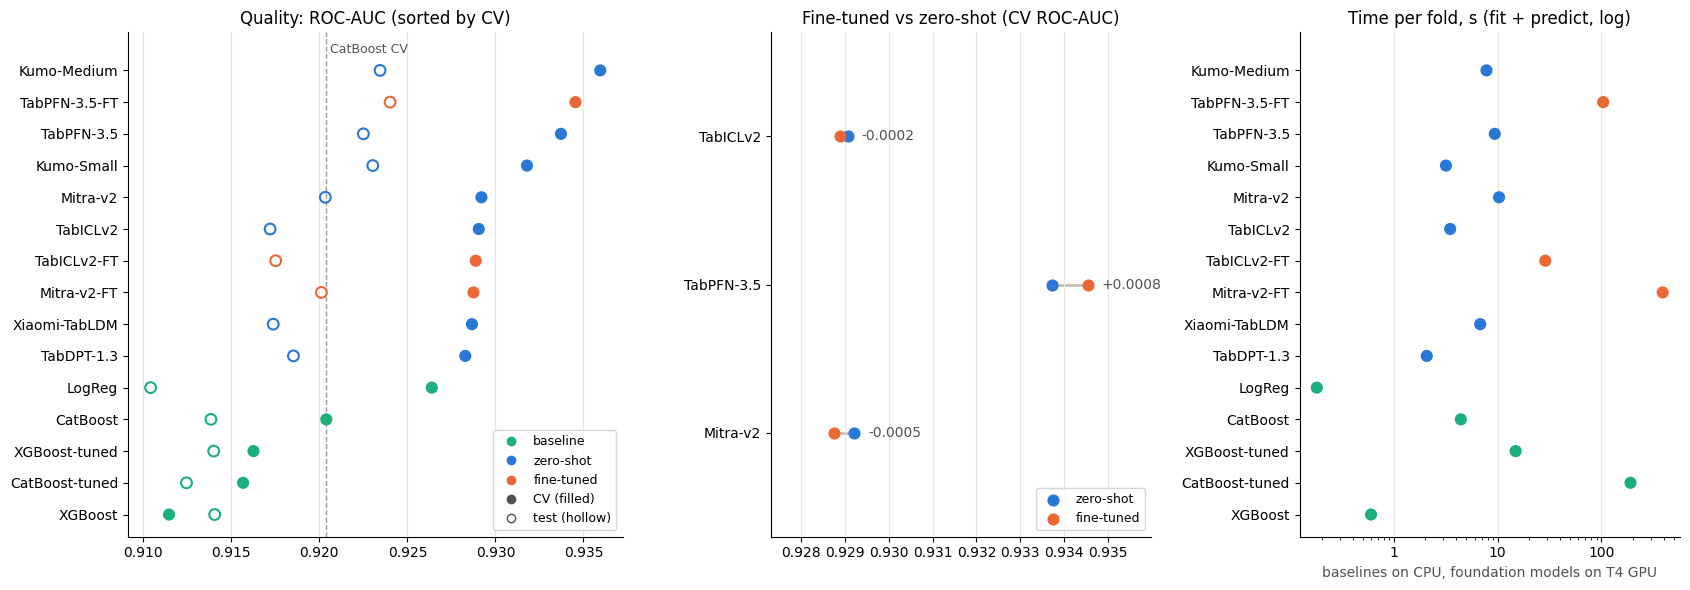

Saved to Drive


In [14]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, NullFormatter
from sklearn.metrics import roc_auc_score

BASE = ['LogReg', 'CatBoost', 'CatBoost-tuned', 'XGBoost', 'XGBoost-tuned']
ZS   = ['TabICLv2', 'TabPFN-3.5', 'Kumo-Small', 'Kumo-Medium', 'Mitra-v2', 'TabDPT-1.3', 'Xiaomi-TabLDM']
FT   = ['TabICLv2-FT', 'TabPFN-3.5-FT', 'Mitra-v2-FT']
kind = {**dict.fromkeys(BASE, 'baseline'), **dict.fromkeys(ZS, 'zero-shot'), **dict.fromkeys(FT, 'fine-tuned')}
TEST = [k for k, v in results['CatBoost'].items() if k != 'oof' and np.ndim(v) == 1 and len(v) == len(y_test)][0]
folds = list(skf.split(X_train, y_train))

def cv_auc(m):                                   # среднее AUC по 5 фолдам (как в run_cv)
    oof = np.asarray(results[m]['oof'])
    return np.mean([roc_auc_score(y_train.iloc[va], oof[va]) for _, va in folds])

# 1. Рейтинг по качеству
rank = pd.DataFrame({'type': kind,
                     'CV AUC': {m: cv_auc(m) for m in kind},
                     'test AUC': {m: roc_auc_score(y_test, results[m][TEST]) for m in kind}})
rank = rank.sort_values('CV AUC', ascending=False)
print('1. Quality Ranking'); display(rank.round(4))

# 2. Fine-tuned vs zero-shot
pairs = ['TabICLv2', 'TabPFN-3.5', 'Mitra-v2']
ft = pd.DataFrame({'CV zero-shot':  rank.loc[pairs, 'CV AUC'].values,
                   'CV fine-tuned': rank.loc[[p + '-FT' for p in pairs], 'CV AUC'].values}, index=pairs)
ft['Δ (FT − ZS)'] = ft['CV fine-tuned'] - ft['CV zero-shot']
print('2. Fine-tuned vs zero-shot'); display(ft.round(4))

# 3. Скорость и железо (из log)
lg = pd.DataFrame(log).drop_duplicates('model', keep='last').set_index('model').reindex(rank.index)
speed = lg.select_dtypes('number')
speed = speed[[c for c in speed.columns if any(k in c for k in ('fit', 'predict', 'latency', 'peak'))]]
if 'device' in lg: speed.insert(0, 'device', lg['device'])
print('3. Speed and device'); display(speed.round(2))

# ---------- график ----------
col = {'baseline': '#1baf7a', 'zero-shot': '#2a78d6', 'fine-tuned': '#eb6834'}
fig, ax = plt.subplots(1, 3, figsize=(17, 6), gridspec_kw={'width_ratios': [1.3, 1, 1]})
r = rank.iloc[::-1]; y = np.arange(len(r)); c = [col[t] for t in r['type']]

ax[0].scatter(r['CV AUC'], y, c=c, s=60, zorder=3)
ax[0].scatter(r['test AUC'], y, facecolors='none', edgecolors=c, s=60, lw=1.5, zorder=3)
ax[0].axvline(rank.loc['CatBoost', 'CV AUC'], color='#9a9a96', lw=1, ls='--', zorder=1)
ax[0].set_ylim(-0.7, len(r) + 0.2)
ax[0].text(rank.loc['CatBoost', 'CV AUC'], len(r) - 0.45, ' CatBoost CV', color='#52514e', fontsize=9)
ax[0].set_yticks(y, r.index); ax[0].set_title('Quality: ROC-AUC (sorted by CV)')
ax[0].legend(handles=[Line2D([], [], marker='o', ls='', color=v, label=k) for k, v in col.items()] +
                     [Line2D([], [], marker='o', ls='', color='#52514e', label='CV (filled)'),
                      Line2D([], [], marker='o', ls='', color='#52514e', mfc='none', label='test (hollow)')],
             loc='lower right', fontsize=9)

yy = np.arange(len(ft))[::-1]
for yi, (_, row) in zip(yy, ft.iterrows()):
    ax[1].plot([row['CV zero-shot'], row['CV fine-tuned']], [yi, yi], color='#c3c2b7', lw=2, zorder=1)
    ax[1].annotate(f"{row['Δ (FT − ZS)']:+.4f}", (max(row['CV zero-shot'], row['CV fine-tuned']), yi),
                   xytext=(10, 0), textcoords='offset points', va='center', fontsize=10, color='#52514e')
ax[1].scatter(ft['CV zero-shot'], yy, color=col['zero-shot'], s=60, zorder=3, label='zero-shot')
ax[1].scatter(ft['CV fine-tuned'], yy, color=col['fine-tuned'], s=60, zorder=3, label='fine-tuned')
ax[1].set_yticks(yy, ft.index); ax[1].set_ylim(-0.7, len(ft) - 0.3)
ax[1].set_title('Fine-tuned vs zero-shot (CV ROC-AUC)'); ax[1].legend(loc='lower right', fontsize=9)
ax[1].margins(x=0.25)

t = lg.loc[r.index, [k for k in ('fit_s', 'predict_s') if k in lg]].sum(axis=1)
ax[2].scatter(t, y, c=c, s=60, zorder=3)
ax[2].set_xscale('log'); ax[2].set_yticks(y, r.index); ax[2].set_ylim(ax[0].get_ylim())
ax[2].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}')); ax[2].xaxis.set_minor_formatter(NullFormatter())
ax[2].set_title('Time per fold, s (fit + predict, log)')
ax[2].set_xlabel('baselines on CPU, foundation models on T4 GPU', color='#52514e')

for a in ax:
    a.grid(axis='x', color='#e6e5e0', lw=0.8, zorder=0)
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{SAVE}/final_comparison.png', dpi=200, bbox_inches='tight'); plt.show()

rank.to_csv(f'{SAVE}/final_rank.csv'); ft.to_csv(f'{SAVE}/final_ft_vs_zs.csv'); speed.to_csv(f'{SAVE}/final_speed.csv')
print('Saved to Drive')